# FinSight RAG walkthrough

This notebook shows how FinSight answers questions about what a filing **says**. Numbers still come from XBRL.

1. **Why RAG?** Compare whole filings with the sections a question needs.
2. **Split** a filing into Items and paragraphs.
3. **Index** every downloaded filing into the vector DB (Qdrant): an embedding and BM25 keyword weights per paragraph.
4. **Retrieve** evidence in *section* mode and *search* mode.
5. **Hand off** to shared memory and build the Mistral prompt. The Mistral call is optional.
6. **Eval** the prose questions from `FinSight_RAG_eval_set.xlsx` and check whether the evidence fits in context.
7. **RQ1 ablation:** compare BM25, embeddings and hybrid search on the same questions (hit@5, recall@5, MRR).

**Before start:** run `python scripts/build_db.py` so `data/finsight.db` has filings with downloaded documents.

**Vector DB:** by default the notebook uses an embedded Qdrant in `data/qdrant/`, which only one process can open at a time, so close the Streamlit app first. To share one index with the app, start a server (`docker run -p 6333:6333 qdrant/qdrant`) and set `FINSIGHT_QDRANT_URL=http://localhost:6333`. The embedding model is `FINSIGHT_EMBED_MODEL` (default `BAAI/bge-small-en-v1.5`, about a 70 MB download the first time).

In [ ]:
# %pip install -r requirements.txt

  Using cached fastembed-0.9.1-py3-none-any.whl.metadata (10 kB)
  Using cached loguru-0.7.3-py3-none-any.whl.metadata (22 kB)
  Using cached mmh3-5.3.1-cp313-cp313-macosx_11_0_arm64.whl.metadata (13 kB)
  Using cached py_rust_stemmers-0.1.8-cp313-cp313-macosx_11_0_arm64.whl.metadata (3.5 kB)
Using cached fastembed-0.9.1-py3-none-any.whl (150 kB)
Using cached loguru-0.7.3-py3-none-any.whl (61 kB)
Using cached mmh3-5.3.1-cp313-cp313-macosx_11_0_arm64.whl (39 kB)
Using cached py_rust_stemmers-0.1.8-cp313-cp313-macosx_11_0_arm64.whl (275 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [fastembed]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import os, re, sys, sqlite3, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)   # relative paths (data/qdrant, data/finsight.db) resolve to the project root, same as the app
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from finsight import config
from finsight.datastore import db, api
from finsight.rag import index_all, retrieve, search, get_section, guess_topics, to_cavm, SEARCH_MODES
from finsight.rag.eval import evaluate
from finsight.rag.sections import split_filing
from finsight.rag.retrieve import est_tokens, TOKENS_PER_WORD

try:
    from finsight.rag import get_store
except ImportError:
    try:
        from finsight.rag.store import get_store
    except ImportError:
        from finsight.rag.index import get_store

In [7]:
pd.set_option("display.max_colwidth", 90)
conn = db.connect()

# Open the vector DB once per kernel. Re-running this cell reuses the open client
# instead of opening a second one, which is what caused the "AlreadyLocked" error.
if "store" not in globals():
    store = get_store()       # loads the embedding model once

print("project root:", ROOT)
print("database:", config.DB_PATH)
print(f"vector DB: {store.collection} · embedder: {store.dense.name} ({store.dense.dim}-dim)")
pd.read_sql("SELECT ticker, form, COUNT(*) AS filings, SUM(local_path IS NOT NULL) AS downloaded "
            "FROM filings GROUP BY ticker, form ORDER BY ticker, form", conn)

project root: /Users/annaphan/Documents/4_Github/AI-Stock-Research-and-Earnings-Assistant
database: data/finsight.db
vector DB: finsight_passages · embedder: BAAI/bge-small-en-v1.5 (384-dim)


,ticker,form,filings,downloaded
0,AAPL,10-K,3,3
1,AAPL,10-Q,9,9
2,AAPL,8-K,26,12
3,AMD,10-K,3,3
4,AMD,10-Q,9,9
5,AMD,8-K,38,12
6,AMZN,10-K,3,3
7,AMZN,10-Q,9,9
8,AMZN,8-K,31,12
9,GOOGL,10-K,3,3


In [10]:
# Pick the company to explore. Falls back to the first ticker with a downloaded 10-K/10-Q.
TICKER = "NVDA"
have = [r[0] for r in conn.execute(
    "SELECT DISTINCT ticker FROM filings WHERE local_path IS NOT NULL AND form IN ('10-K','10-Q')")]
if TICKER not in have:
    TICKER = have[0] if have else None
assert TICKER, "No downloaded 10-K/10-Q yet: run scripts/build_db.py"
NAME = (api.get_company(TICKER, conn) or {}).get("name") or TICKER
print(TICKER, "-", NAME)

NVDA - NVIDIA CORP


## 1. Why RAG? A whole filing is too big, but one section isn't

`api.get_filing_text()` returns the whole document. Most of a 10-K is financial tables and boilerplate that a question about risks or management commentary doesn't need.

In [11]:
latest = {f["form"]: f for f in reversed(api.list_filings(TICKER, limit=50, conn=conn))
          if f["local_path"] and f["form"] in ("10-K", "10-Q")}
rows = []
for form, f in latest.items():
    text = api.get_filing_text(f["accession"], conn)["text"]
    w = len(text.split())
    rows.append({"form": form, "filing": f["fiscal_label"] or f["filing_date"], "accession": f["accession"],
                 "words": w, "≈ tokens": est_tokens(w)})
whole = pd.DataFrame(rows)
whole

,form,filing,accession,words,≈ tokens
0,10-Q,Q2 FY2027,0001045810-26-000075,21939,29618
1,10-K,FY2026,0001045810-26-000021,50081,67609


## 2. Split one filing into Items and paragraphs

`split_filing` finds the Item headings and skips the table of contents. Each section gets a **topic** that means the same thing in every form: `risk_factors` is Item 1A in a 10-K and Part II Item 1A in a 10-Q. Table rows are kept as `kind="table"` and are never searched.

In [12]:
f = latest.get("10-K") or latest.get("10-Q")
text = api.get_filing_text(f["accession"], conn)["text"]
sections = split_filing(text, f["form"])
secs = pd.DataFrame([{
    "part": s.part, "item": s.item, "topic": s.topic, "title": s.title[:60],
    "prose words": s.n_words, "≈ tokens": est_tokens(s.n_words),
    "paragraphs": sum(p.kind == "text" for p in s.passages),
    "table rows": sum(p.kind == "table" for p in s.passages),
} for s in sections])
print(f"{TICKER} {f['form']} {f['fiscal_label']}: {len(sections)} sections")
secs

NVDA 10-K FY2026: 23 sections


,part,item,topic,title,prose words,≈ tokens,paragraphs,table rows
0,,1,business,Business,6946,9377,95,0
1,,1A,risk_factors,Risk Factors,16951,22884,229,0
2,,1B,unresolved_staff_comments,Unresolved Staff Comments,1,1,1,0
3,,1C,cybersecurity,Cybersecurity,543,733,7,0
4,,2,properties,Properties,137,185,1,0
5,,3,legal,Legal Proceedings,31,42,1,0
6,,4,mine_safety,Mine Safety Disclosures,2,3,1,0
7,,5,market_for_equity,"Market for Registrant's Common Equity, Related Stockholder M",716,967,15,8
8,,6,reserved,[Reserved],0,0,0,0
9,,7,mdna,Management's Discussion and Analysis of Financial Condition,4672,6307,82,44


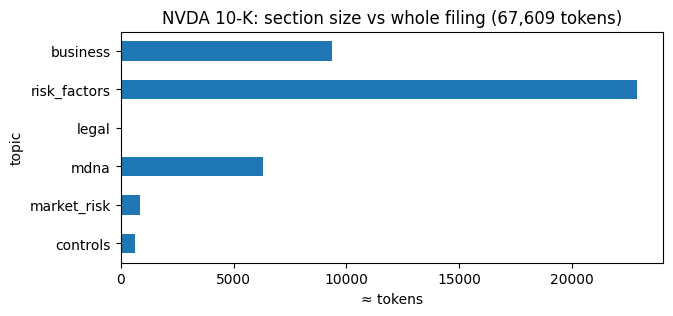

In [13]:
# The sections most questions need, as a share of the whole filing
key = secs[secs.topic.isin(["risk_factors", "mdna", "legal", "business", "controls", "market_risk"])]
total = whole.loc[whole.form == f["form"], "≈ tokens"].iloc[0]
ax = key.set_index("topic")["≈ tokens"].plot.barh(figsize=(7, 3),
        title=f"{TICKER} {f['form']}: section size vs whole filing ({total:,} tokens)")
ax.set_xlabel("≈ tokens"); ax.invert_yaxis();

In [14]:
# What a paragraph looks like: text, nearest sub-heading, and a stable order number
rf = next(s for s in sections if s.topic == "risk_factors")
for p in rf.passages[:3]:
    print(f"[{p.seq}] heading={p.heading!r}  ({p.n_words} words)\n{p.text[:400]}\n")

[0] heading=''  (71 words)
The following risk factors should be considered in addition to the other information in this Annual Report on Form 10-K. The following risks could harm our business, financial condition, results of operations or reputation, which could cause our stock price to decline. Additional risks, trends and uncertainties not presently known to us or that we currently believe are immaterial may also harm our

[1] heading='Risks Related to Our Industry and Markets'  (17 words)
•Failure to meet the evolving needs of our industry and markets may adversely impact our financial results.

[2] heading='Risks Related to Our Industry and Markets'  (10 words)
•Competition could adversely impact our market share and financial results.



## 3. Build the index

Each text paragraph becomes one point in the vector DB. A point holds two vectors: **dense**, the embedding, which captures meaning, and **bm25**, keyword weights. Its payload carries the ticker, form, accession, topic, section, text and citation details, so every search can be filtered by company, filing and section.

Indexing is safe to re-run: filings already in the vector DB are skipped. `found_items = False` means no Item headings were found and the filing was indexed as full text, so check those. Embedding is the slow part: roughly a few minutes for 10 companies on a laptop CPU, faster on the GPU.

8-K press releases are in Exhibit 99.1, which `build_db.py` doesn't download. Run `python scripts/build_rag_index.py --press-releases` to fetch them first.

In [15]:
t0 = time.time()
results = index_all(conn, store=store)
print(f"indexed {sum('passages' in r for r in results)} filings in {time.time() - t0:.0f}s, "
      f"skipped {sum(bool(r.get('skipped')) for r in results)}, errors {sum('error' in r for r in results)} "
      f"· {store.count():,} paragraphs in the vector DB")
for r in results:
    if "error" in r:
        print("  ERROR", r["accession"], r["error"])
pd.DataFrame([{"ticker": t, "form": f, "paragraphs": store.count(ticker=t, forms=[f])}
              for t, f in conn.execute("SELECT DISTINCT ticker, form FROM filings WHERE local_path IS NOT NULL ORDER BY 1, 2")])

indexed 0 filings in 4s, skipped 252, errors 0 · 75,893 paragraphs in the vector DB


,ticker,form,paragraphs
0,AAPL,10-K,1340
1,AAPL,10-Q,1591
2,AAPL,8-K,84
3,AMD,10-K,2411
4,AMD,10-Q,3686
5,AMD,8-K,147
6,AMZN,10-K,1973
7,AMZN,10-Q,3530
8,AMZN,8-K,72
9,GOOGL,10-K,3289


## 4. Retrieve evidence

`retrieve(question, ticker)` works in three steps:

1. Picks the topic(s) from the question. The router can pass `topics=[...]` instead.
2. Takes those sections from the newest filing. If a 10-Q's Risk Factors section only says "no material changes", it also adds the latest 10-K's.
3. Returns the whole section if it fits `budget_tokens` (**section** mode). Otherwise it searches inside it and keeps the best paragraphs (**search** mode). The default search is **hybrid**: embeddings and BM25 ranked separately, then merged with reciprocal rank fusion. `search_mode="dense"` or `"sparse"` picks one.
4. One exception: a *summary* question ("summarize the main risks") over budget gets the section from the top until the budget is used (**section**, `truncated=True`), because a search would miss most of it.
5. If the company has no indexed filing of the requested form, the mode is **none** and the evidence list is empty.

In [16]:
for q in [f"What new risks did {NAME} flag in its latest filing?",
          "What drove the change in gross margin?",
          "Is the company involved in any significant legal proceedings?",
          "What does the company say about export controls to China?",
          "Any material weakness in internal control?",
          "What was revenue last quarter?"]:
    print(f"{guess_topics(q)!s:28}  {q}")

['risk_factors']              What new risks did NVIDIA CORP flag in its latest filing?
['mdna']                      What drove the change in gross margin?
['legal']                     Is the company involved in any significant legal proceedings?
['risk_factors']              What does the company say about export controls to China?
['controls']                  Any material weakness in internal control?
[]                            What was revenue last quarter?


In [17]:
def show(r, n=5, chars=260):
    cut = " (cut at budget)" if r.get("truncated") else ""
    how = f" ({r['search_mode']})" if r.get("search_mode") else ""
    print(f"mode={r['mode']}{how}{cut}  topics={r['topics']}  ≈{r['tokens']:,} tokens  {len(r['evidence'])} paragraphs")
    for i, e in enumerate(r["evidence"][:n], 1):
        print(f"\n[S{i}] {e.form} {e.fiscal_label} · {e.section[:60]}"
              + (f" · {e.heading[:40]}" if e.heading else "")
              + (f"  (score {e.score:.3f})" if e.score is not None else ""))
        print("     " + e.text[:chars] + ("…" if len(e.text) > chars else ""))

# Section mode: a small section comes back whole, in reading order
show(retrieve("Is the company involved in any significant legal proceedings?", TICKER, conn=conn))

mode=section  topics=['legal']  ≈51 tokens  1 paragraphs

[S1] 10-Q Q2 FY2027 · Part II Item 1 · Legal Proceedings
     Refer to Note 10 of the Notes to Condensed Consolidated Financial Statements in Part I, Item 1 of this Quarterly Report on Form 10-Q for a discussion of significant developments in our legal proceedings since January 25, 2026.


In [18]:
# Search mode: 10-K Risk Factors is usually larger than the 12K default budget,
# so retrieve() searches inside it (hybrid) and keeps the best paragraphs
show(retrieve("What does the company say about tariffs, trade restrictions and China?", TICKER,
              forms=("10-K",), conn=conn))

mode=search (hybrid)  topics=['risk_factors']  ≈1,729 tokens  8 paragraphs

[S1] 10-K FY2026 · Item 1A · Risk Factors · Risks Related to Regulatory, Legal, Our   (score 0.591)
     In the event that we are able to sell licensed products into the China market, we may not be able to pass along all or any of the tariff to our customers, and may be subject to litigation, increased costs, and a harmed competitive position.

[S2] 10-K FY2026 · Item 1A · Risk Factors · Risks Related to Our Global Operating Bu  (score 0.534)
     We sell our products internationally, and we also have operations and conduct business internationally. Our semiconductor wafers are manufactured, assembled, tested and packaged by third parties located outside of the United States, and we generated 31% of our…

[S3] 10-K FY2026 · Item 1A · Risk Factors · Risks Related to Regulatory, Legal, Our   (score 0.458)
     In addition to export controls, the USG may impose restrictions on the import and sale of products that 

In [19]:
# Same question, bigger budget (e.g. a 128K hosted Mistral model): the whole section fits
r = retrieve("What does the company say about tariffs, trade restrictions and China?", TICKER,
             forms=("10-K",), budget_tokens=60_000, conn=conn)
print(r["mode"], f"≈{r['tokens']:,} tokens", len(r["evidence"]), "paragraphs")

section ≈22,878 tokens 229 paragraphs


In [20]:
# Summary question over budget: read the section from the top instead of keyword search
show(retrieve(f"Summarize the main risks in {NAME}'s latest 10-K.", TICKER, forms=("10-K",),
              topics=["risk_factors"], conn=conn), n=3, chars=160)

mode=section (cut at budget)  topics=['risk_factors']  ≈11,913 tokens  154 paragraphs

[S1] 10-K FY2026 · Item 1A · Risk Factors
     The following risk factors should be considered in addition to the other information in this Annual Report on Form 10-K. The following risks could harm our busi…

[S2] 10-K FY2026 · Item 1A · Risk Factors · Risks Related to Our Industry and Market
     •Failure to meet the evolving needs of our industry and markets may adversely impact our financial results.

[S3] 10-K FY2026 · Item 1A · Risk Factors · Risks Related to Our Industry and Market
     •Competition could adversely impact our market share and financial results.


### Same question, three search modes

A paraphrase question shows the difference. Here the question avoids the filing's own words ("limits on selling chips" rather than "export restrictions"):

- **sparse (BM25)** needs shared words.
- **dense** matches meaning.
- **hybrid** keeps paragraphs that rank well in either.

Search runs across every indexed company, which is useful for checking the index.

In [21]:
Q = "Do government limits on selling products to certain countries affect the company?"
cmp = []
for m in SEARCH_MODES:
    for rank, e in enumerate(search(Q, topics=["risk_factors"], k=5, mode=m), 1):
        cmp.append({"mode": m, "rank": rank, "ticker": e.ticker, "form": e.form,
                    "score": round(e.score, 3), "heading": e.heading[:40], "text": e.text[:120] + "…"})
pd.DataFrame(cmp)

,mode,rank,ticker,form,score,heading,text
0,sparse,1,JPM,10-K,17.415,•actions by or at the direction of gover,JPMorganChase's business and operations could be negatively affected by governmental p...
1,sparse,2,JPM,10-K,16.781,•potential expropriation or nationalizat,"In addition, JPMorgan Chase's relationships or ability to transact with clients and cu..."
2,sparse,3,JPM,10-K,16.370,Part I,"In addition, JPMorganChase has been and expects that it will continue to be criticized..."
3,sparse,4,JPM,10-K,16.311,Summary,"•Legal and Regulatory risks, including the impact of extensive supervision and regulat..."
4,sparse,5,JPM,10-K,15.790,Summary,"•Regulatory risks, including the impact that applicable laws, rules and regulations in..."
5,dense,1,AMD,10-Q,0.839,Legal and Regulatory Risks,•Government actions and regulations may limit our ability to export our products to ce...
6,dense,2,AMD,10-K,0.839,Legal and Regulatory Risks,•Government actions and regulations may limit our ability to export our products to ce...
7,dense,3,AMD,10-Q,0.839,Legal and Regulatory Risks,•Government actions and regulations may limit our ability to export our products to ce...
8,dense,4,AMD,10-Q,0.839,Legal and Regulatory Risks,•Government actions and regulations may limit our ability to export our products to ce...
9,dense,5,AMD,10-Q,0.837,Legal and Regulatory Risks,"However, the restrictions can be reimposed at any time. These restrictive governmental..."


## 5. Hand off to shared memory and build the prompt

`to_cavm()` labels each paragraph `S1, S2…` with its citation. That list is what the retriever `put`s into shared memory. The Report agent reads it and cites the labels. The prompt below is the **Write + check** step.

In [22]:
QUESTION = "Is the company involved in any significant legal proceedings?"
r = retrieve(QUESTION, TICKER, conn=conn)
evidence = to_cavm(r["evidence"])
pd.DataFrame(evidence)[["id", "citation", "heading", "n_words"]].head(10)

,id,citation,heading,n_words
0,S1,NVDA 10-Q Q2 FY2027 · Part II Item 1 · Legal Proceedings (filed 2026-08-26) https://ww...,,38


In [23]:
SYSTEM = (
    "You are FinSight, a research assistant for SEC filings. Answer ONLY from the evidence. "
    "End every sentence that uses evidence with its label, e.g. [S2]. If the evidence does not "
    "answer the question, say so. Never give buy, hold or sell advice."
)

def build_prompt(question: str, evidence: list[dict]) -> list[dict]:
    blocks = "\n\n".join(f"[{e['id']}] {e['citation']}\n{e['text']}" for e in evidence)
    return [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"Evidence:\n\n{blocks}\n\nQuestion: {question}"}]

messages = build_prompt(QUESTION, evidence)
prompt_words = sum(len(m["content"].split()) for m in messages)
print(f"prompt ≈ {est_tokens(prompt_words):,} tokens\n")
print(messages[1]["content"][:1500], "…")

prompt ≈ 144 tokens

Evidence:

[S1] NVDA 10-Q Q2 FY2027 · Part II Item 1 · Legal Proceedings (filed 2026-08-26) https://www.sec.gov/Archives/edgar/data/1045810/000104581026000075/nvda-20260726.htm
Refer to Note 10 of the Notes to Condensed Consolidated Financial Statements in Part I, Item 1 of this Quarterly Report on Form 10-Q for a discussion of significant developments in our legal proceedings since January 25, 2026.

Question: Is the company involved in any significant legal proceedings? …


In [24]:
# Optional: call Mistral. Needs MISTRAL_API_KEY in .env; skipped otherwise.
try:
    from dotenv import load_dotenv; load_dotenv(ROOT / ".env")
except ImportError:
    pass
import json, urllib.request

def ask_mistral(messages, model=os.getenv("MISTRAL_MODEL", "mistral-small-latest")):
    req = urllib.request.Request(
        "https://api.mistral.ai/v1/chat/completions",
        data=json.dumps({"model": model, "messages": messages, "temperature": 0.1}).encode(),
        headers={"Authorization": f"Bearer {os.environ['MISTRAL_API_KEY']}",
                 "Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=60) as resp:
        return json.load(resp)["choices"][0]["message"]["content"]

answer = None
if os.getenv("MISTRAL_API_KEY"):
    answer = ask_mistral(messages)
    print(answer)
else:
    print("MISTRAL_API_KEY not set: skipping the LLM call.")

MISTRAL_API_KEY not set: skipping the LLM call.


In [25]:
# Citation check: every sentence cites a label, and every label exists in the evidence
def check_citations(answer: str, evidence: list[dict]) -> dict:
    valid = {e["id"] for e in evidence}
    cited = re.findall(r"\[(S\d+)\]", answer)
    sentences = [s for s in re.split(r"(?<=[.!?])\s+", answer.strip()) if len(s.split()) > 4]
    uncited = [s for s in sentences if not re.search(r"\[S\d+\]", s)]
    return {"labels cited": sorted(set(cited), key=lambda x: int(x[1:])),
            "unknown labels": sorted(set(cited) - valid),
            "sentences without a citation": len(uncited), "sentences": len(sentences)}

if answer:
    check_citations(answer, evidence)
else:
    # what the check reports on a sample answer
    check_citations("Apple faces an antitrust suit from the DOJ [S2]. It is also appealing the Epic ruling [S3]. "
                    "This is a big risk for the stock.", evidence)

## 6. Eval: do the prose questions fit, and which retrieval mode do they use?

These are the questions from `FinSight_RAG_eval_set.xlsx` that need filing prose, phrased for the selected company. For each one, the table shows the mode, the paragraphs returned, and the evidence size compared with the two context windows. Paste **Result** into the workbook once Mistral has answered.

The fixed overhead (system prompt, question, other evidence and the answer reserve) is 4,700 tokens, the same as in the workbook.

In [26]:
OVERHEAD = 4_700
MODEL_A, MODEL_B = 128_000, 32_768        # hosted Mistral vs small local model
PEER = next((t for t in have if t != TICKER), None)

EVAL = [  # (workbook id, question, retrieve() kwargs)
    ("Q01", f"What new risk factors did {NAME} add in its latest 10-Q?", dict(forms=("10-Q",))),
    ("Q02", "What does management say drove the change in gross margin this quarter?", dict(forms=("10-Q",))),
    ("Q05", f"Is {NAME} involved in any significant legal proceedings?", {}),
    ("Q07", f"What does {NAME} say about tariffs and trade restrictions?", {}),
    ("Q08", f"Summarize the main risks in {NAME}'s latest 10-K.", dict(forms=("10-K",), topics=["risk_factors"])),
    ("Q09", f"How does {NAME} describe its competitive position?", dict(forms=("10-K",))),
    ("Q11", f"How have {NAME}'s risk factors changed over the last four filings?", dict(topics=["risk_factors"], n_filings=4)),
    ("Q14", f"Did today's price move relate to risks {NAME} flagged in its 10-Q?", dict(forms=("10-Q",), topics=["risk_factors"])),
    ("Q16", f"What critical accounting estimates does {NAME} highlight?", dict(forms=("10-K",))),
    ("Q17", "What was EPS last quarter and how did management explain it?", dict(forms=("10-Q",), topics=["mdna"])),
    ("Q19", f"Did {NAME} disclose any material weakness in internal controls?", {}),
    ("Q20", f"What did {NAME} disclose in its 8-K filings this quarter?", dict(forms=("8-K",), n_filings=3, topics=[])),
]

rows = []
for qid, q, kw in EVAL:
    r = retrieve(q, TICKER, conn=conn, **kw)
    total = r["tokens"] + OVERHEAD
    rows.append({"id": qid, "question": q, "topics": ",".join(r["topics"]) or "(search all)",
                 "mode": r["mode"] + (" (cut)" if r.get("truncated") else ""), "paragraphs": len(r["evidence"]),
                 "filings used": len({e.passage_id.split('/')[0] for e in r["evidence"]}),
                 "evidence tokens": r["tokens"], "prompt tokens": total,
                 "fits 128K": total <= MODEL_A, "fits 32K": total <= MODEL_B,
                 "found nothing": not r["evidence"]})

if PEER:   # Q15: two companies side by side
    peer_name = (api.get_company(PEER, conn) or {}).get("name") or PEER
    q = f"Compare how {NAME} and {peer_name} describe AI-related risks."
    rs = [retrieve(q, t, forms=("10-K",), topics=["risk_factors"], conn=conn) for t in (TICKER, PEER)]
    tok = sum(r["tokens"] for r in rs)
    rows.append({"id": "Q15", "question": q, "topics": "risk_factors", "mode": "/".join(r["mode"] for r in rs),
                 "paragraphs": sum(len(r["evidence"]) for r in rs), "filings used": 2,
                 "evidence tokens": tok, "prompt tokens": tok + OVERHEAD,
                 "fits 128K": tok + OVERHEAD <= MODEL_A, "fits 32K": tok + OVERHEAD <= MODEL_B,
                 "found nothing": not any(r["evidence"] for r in rs)})

ev = pd.DataFrame(rows).sort_values("id").reset_index(drop=True)
ev

,id,question,topics,mode,paragraphs,filings used,evidence tokens,prompt tokens,fits 128K,fits 32K,found nothing
0,Q01,What new risk factors did NVIDIA CORP add in its latest 10-Q?,risk_factors,section,51,1,7107,11807,True,True,False
1,Q02,What does management say drove the change in gross margin this quarter?,mdna,section,78,1,6831,11531,True,True,False
2,Q05,Is NVIDIA CORP involved in any significant legal proceedings?,legal,section,1,1,51,4751,True,True,False
3,Q07,What does NVIDIA CORP say about tariffs and trade restrictions?,risk_factors,section,51,1,7107,11807,True,True,False
4,Q08,Summarize the main risks in NVIDIA CORP's latest 10-K.,risk_factors,section (cut),154,1,11913,16613,True,True,False
5,Q09,How does NVIDIA CORP describe its competitive position?,business,section,95,1,9378,14078,True,True,False
6,Q11,How have NVIDIA CORP's risk factors changed over the last four filings?,risk_factors,search,8,4,1078,5778,True,True,False
7,Q14,Did today's price move relate to risks NVIDIA CORP flagged in its 10-Q?,risk_factors,section,51,1,7107,11807,True,True,False
8,Q15,Compare how NVIDIA CORP and Apple Inc. describe AI-related risks.,risk_factors,search/search,16,2,2575,7275,True,True,False
9,Q16,What critical accounting estimates does NVIDIA CORP highlight?,mdna,section,82,1,6306,11006,True,True,False


13 prose questions · section mode 10 · search mode 3 · no filings 0
fit 128K: 13/13 · fit 32K: 13/13 · largest prompt ≈16,613 tokens


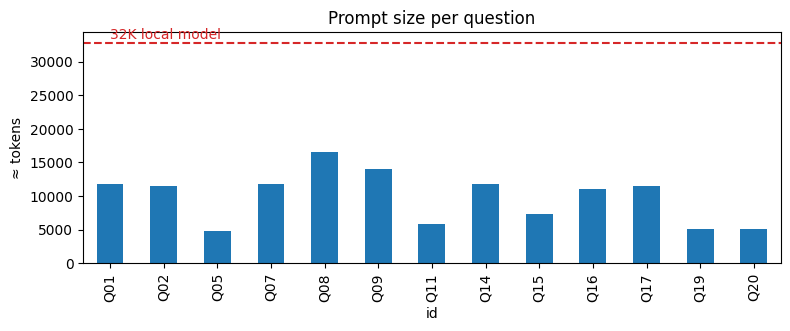

In [27]:
print(f"{len(ev)} prose questions · section mode {sum(ev['mode'].str.startswith('section'))} · "
      f"search mode {sum(ev['mode'].str.contains('search'))} · no filings {sum(ev['mode'] == 'none')}")
print(f"fit 128K: {ev['fits 128K'].sum()}/{len(ev)} · fit 32K: {ev['fits 32K'].sum()}/{len(ev)} · "
      f"largest prompt ≈{ev['prompt tokens'].max():,} tokens")
gaps = ev[ev["found nothing"] | (ev["filings used"] < 1)]
if len(gaps):
    print("\nNo evidence found (no filing of that form indexed for this company):", ", ".join(gaps["id"]))
ax = ev.set_index("id")["prompt tokens"].plot.bar(figsize=(9, 3), title="Prompt size per question")
ax.axhline(MODEL_B, ls="--", c="tab:red"); ax.text(0, MODEL_B * 1.02, "32K local model", color="tab:red")
ax.set_ylabel("≈ tokens");

In [28]:
# Save for the workbook ('Questions' sheet) and for comparing runs as the splitter changes
out = ROOT / "data" / "rag_eval_run.csv"
ev.to_csv(out, index=False)
print("saved", out)

saved /Users/annaphan/Documents/4_Github/AI-Stock-Research-and-Earnings-Assistant/data/rag_eval_run.csv


## 7. RQ1 ablation: BM25 vs embeddings vs hybrid

The same questions go through all three search modes. A paragraph counts as relevant when it matches the case's `gold_regex` (quick to write, a bit loose) or appears in `gold_ids` (exact, and better for the final report).

| Metric | What it measures |
|---|---|
| **hit@5** | Share of questions with at least one relevant paragraph in the top 5 |
| **recall@5** | Share of the gold paragraphs found (the same as hit@5 for regex cases) |
| **MRR** | How high the first relevant paragraph ranks (1.0 means always first) |

The questions use generic wording so they work for any of the 10 companies. Several deliberately avoid the filing's own words, to test whether embeddings help.

In [29]:
CASES = [
    {"id": "tariffs",     "question": "How could tariffs and trade disputes hurt the company?",
     "topics": ["risk_factors"], "gold_regex": r"tariff|trade (restriction|polic|disput|tension)"},
    {"id": "export",      "question": "Do government limits on selling products to certain countries matter?",
     "topics": ["risk_factors"], "gold_regex": r"export (control|restriction|licens)|sanction"},
    {"id": "suppliers",   "question": "Does the company rely on a small number of suppliers or manufacturers?",
     "topics": ["risk_factors"], "gold_regex": r"single.source|sole.source|limited number of|contract manufactur|third.party manufactur"},
    {"id": "disasters",   "question": "Could natural disasters, pandemics or wars disrupt operations?",
     "topics": ["risk_factors"], "gold_regex": r"earthquake|pandemic|natural disaster|\bwar\b|terror"},
    {"id": "cyber",       "question": "How could hackers or data breaches affect the business?",
     "topics": ["risk_factors", "cybersecurity"], "gold_regex": r"cyber|breach|ransomware|malicious"},
    {"id": "competition", "question": "How intense is the competition the company faces?",
     "topics": ["risk_factors", "business"], "gold_regex": r"competit"},
    {"id": "talent",      "question": "Does the company depend on hiring and keeping key people?",
     "topics": ["risk_factors"], "gold_regex": r"key (personnel|employees)|attract(ing)?,? (and|or) retain|talent"},
    {"id": "fx-rates",    "question": "How do interest rates and currency moves affect results?",
     "gold_regex": r"interest rate|foreign (currency|exchange)"},
    {"id": "lawsuits",    "question": "Is the company being sued or investigated by regulators?",
     "gold_regex": r"lawsuit|complaint|investigation|antitrust|litigation"},
    {"id": "liquidity",   "question": "Does the company have enough cash to fund its plans?",
     "topics": ["mdna"], "gold_regex": r"liquidity|cash and cash equivalents|sufficient to"},
]
tickers = have if len(have) <= 5 else have[:5]          # keep the first run quick; widen later
cases = [dict(c, id=f"{t}-{c['id']}", ticker=t, n_filings=2) for t in tickers for c in CASES]
rows, summary = evaluate(cases, k=5, conn=conn, store=store)
print(f"{len(cases)} cases · {len(tickers)} companies · embedder {store.dense.name}")
pd.DataFrame(summary)

50 cases · 5 companies · embedder BAAI/bge-small-en-v1.5


,mode,cases,hit@5,recall@5,MRR
0,sparse,50,0.34,0.34,0.233
1,dense,50,0.52,0.52,0.480
2,hybrid,50,0.56,0.56,0.491


Cases where the modes disagree (reciprocal rank, 0 = missed):


mode,dense,hybrid,sparse
id,,,
AAPL-competition,0.33,0.33,0.00
AAPL-cyber,1.00,0.50,0.20
AAPL-lawsuits,1.00,1.00,0.00
AAPL-tariffs,0.00,1.00,1.00
AMD-competition,1.00,1.00,0.00
AMD-cyber,1.00,1.00,0.00
AMD-export,0.33,0.20,0.20
AMD-lawsuits,1.00,1.00,0.00
AMD-suppliers,1.00,1.00,0.00


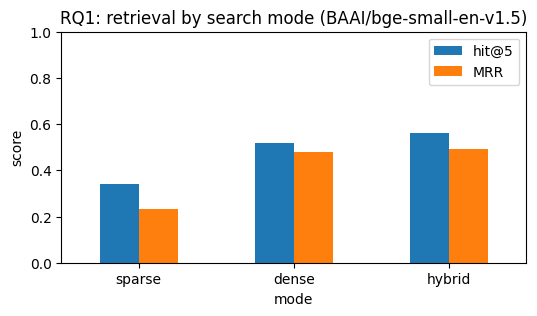

In [30]:
per = pd.DataFrame(rows)
wide = per.pivot_table(index="id", columns="mode", values="rr").round(2)
ax = pd.DataFrame(summary).set_index("mode")[["hit@5", "MRR"]].plot.bar(
    figsize=(6, 3), rot=0, ylim=(0, 1), title=f"RQ1: retrieval by search mode ({store.dense.name})")
ax.set_ylabel("score");
print("Cases where the modes disagree (reciprocal rank, 0 = missed):")
wide[wide.nunique(axis=1) > 1]

In [31]:
# Turn a regex case into exact gold: look at the top hits of every mode, keep the right ones
CASE = cases[0]
seen = {}
for m in SEARCH_MODES:
    for e in search(CASE["question"], CASE["ticker"], CASE.get("topics"), k=5, mode=m, store=store):
        seen.setdefault(e.passage_id, {"passage_id": e.passage_id, "found by": [], "text": e.text[:160] + "…"})
        seen[e.passage_id]["found by"].append(m)
print(CASE["question"])
pd.DataFrame(seen.values())
# then: CASES[0]["gold_ids"] = ["<passage_id>", ...]   and re-run the ablation

How could tariffs and trade disputes hurt the company?


,passage_id,found by,text
0,0000320193-25-000079/1A/p098,"[sparse, hybrid]",The Company distributes its products and certain of its services through third-party c...
1,0000320193-24-000123/1A/p105,"[sparse, hybrid]",The Company distributes its products and certain of its services through third-party c...
2,0000320193-23-000106/1A/p102,[sparse],The Company distributes its products and certain of its services through third-party c...
3,0000320193-23-000106/1A/p010,[sparse],"The Company has a large, global business with sales outside the U.S. representing a ma..."
4,0000320193-25-000057/II-1A/p003,[sparse],"The Company has a large, global business with sales outside the U.S. representing a ma..."
5,0000320193-25-000057/II-1A/p004,"[dense, hybrid]",Trade and other international disputes can also have an adverse impact on the overall ...
6,0000320193-25-000079/1A/p010,"[dense, hybrid]",Trade and other international disputes can also have an adverse impact on the overall ...
7,0000320193-24-000123/1A/p008,"[dense, hybrid]","The Company’s business can be impacted by political events, trade and other internatio..."
8,0000320193-25-000079/1A/p007,[dense],"The Company’s business can be impacted by political events, trade and other internatio..."
9,0000320193-23-000106/1A/p009,[dense],"Political events, trade and other international disputes, war, terrorism, natural disa..."


In [ ]:
out = ROOT / "data" / f"rq1_retrieval_{store.dense.name.replace('/', '_')}.csv"
per.to_csv(out, index=False)
print("saved", out)

## Reading the RQ1 results

- **Hybrid** is usually the safe default. It keeps BM25's precision on exact names (Epic Games, Item 1A, product names) and adds the embeddings' recall on paraphrases.
- **Dense** winning on the reworded questions (export, suppliers, talent) is the case for embeddings. **Sparse** winning on name-heavy questions is the case for keeping BM25.
- Report the numbers per embedding model: change `FINSIGHT_EMBED_MODEL`, rebuild with `python scripts/build_rag_index.py --rebuild`, and re-run this section.
- Before the final report, swap `gold_regex` for hand-checked `gold_ids` on the cases you report.

## Done: release the vector DB

Run this before starting the Streamlit app or another notebook. Only one process can open the embedded Qdrant at a time.

In [32]:
client = getattr(store, "client", None) or getattr(store, "_client", None)
if client is not None:
    client.close()
del store
if hasattr(get_store, "cache_clear"):
    get_store.cache_clear()
conn.close()
print("vector DB released")

vector DB released
